# Undersampling isolado — métricas e diagnóstico

Somente **RandomUnderSampler** reduz a classe legítima até a razão minoria/maioria **0,1**; todas as fraudes originais são preservadas. Não são criadas observações sintéticas.

Experimento de 28/10/2026. **Sem combinação entre samplers.** Random Forest e XGBoost usam os mesmos três folds temporais, StandardScaler e seleção de features aprendida no treino de cada fold. Pesos uniformes em todas as receitas, inclusive o controle sem sampling. **F1 é principal; threshold fixo 0,50** permite comparar receitas sem misturar uma nova escolha de threshold. O artefato histórico com threshold 0,70 e os resultados históricos de TEST ficam preservados.

## Como ler as métricas
Classe positiva: **fraude (Class=1)**. Legítimas são Class=0.
As tabelas mostram porcentagens quando apropriado; os CSVs mantêm valores numéricos.

| Métrica | Significado / denominador |
|---|---|
| Recall | TP/(TP+FN): entre as fraudes reais, quantas foram detectadas? |
| Precision | TP/(TP+FP): entre os alertas gerados, quantos eram fraude real? |
| F1 | Média harmônica simétrica de Precision e Recall. |
| AP | Average Precision: resumo da curva PR ponderado pelo ganho de Recall; usa scores contínuos, maior é melhor. Não é a área trapezoidal PR. |
| ROC-AUC | Qualidade da ordenação fraude vs. legítima; complementar à AP em classe rara. |
| Log Loss / Brier | Erros probabilísticos; menor é melhor, sem comprovar calibração. |
| TP / TN | Fraude detectada / legítima corretamente liberada. |
| FP / FN | Legítima alertada / fraude não detectada. |
| Taxa de alertas | (TP+FP)/n: volume relativo de revisão/bloqueio. |
| FPR | FP/(FP+TN): legítimas que geraram alerta. |
| Parcela de alertas falsos | FP/(FP+TP)=1−Precision: alertas que eram legítimos; denominador diferente da FPR. |
| Taxa de fraude na faixa | Fraudes reais / transações da faixa; descreve rótulos, não erros do modelo. |
| Média e desvio de CV | Resumo entre folds; desvio não é intervalo de confiança nem teste de superioridade. |
| Queda de AP por permutação | Quanto AP cai quando uma feature é embaralhada na validação; escala distinta da correlação. |

As contagens FP/FN médias entre folds podem ser fracionárias. Métrica OOF agregada
difere da média dos folds. 0,000190 em proporção significa **0,0190%**.
“Não definido” indica denominador zero, não score zero.
[Guia completo, fórmulas e limitações](../docs/metrics_guide.md).

In [1]:
# Este notebook só lê artefatos; nenhum modelo é treinado ao abrir.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from fraud_detection.reporting import readable_table

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Abra o notebook pela raiz ou pela pasta notebooks.")
METRICS = ROOT / "reports/metrics"
FIGURES = ROOT / "reports/figures"
EXPERIMENTS = ROOT / "reports/experiments"

def table(name):
    path = METRICS / name
    if not path.exists():
        raise FileNotFoundError(
            f"Artefato ausente: {name}. Execute python -m fraud_detection.sampling_comparison."
        )
    return pd.read_csv(path)

def figure(name, width=1100):
    path = FIGURES / name
    if not path.exists():
        raise FileNotFoundError(
            f"Figura ausente: {name}. Execute python -m fraud_detection.sampling_comparison."
        )
    display(Image(filename=str(path), width=width))

def show(frame):
    display(readable_table(frame))

manifest_path = EXPERIMENTS / "sampling_comparison_manifest.json"
if not manifest_path.exists():
    raise FileNotFoundError(
        "Execute python -m fraud_detection.sampling_comparison para gerar os relatórios."
    )
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
assert manifest["test_evaluated"] is False
assert manifest["primary_model_replaced"] is False

MODE = "under"


## 1. Protocolo, folds e amostragem realmente aplicada
A primeira separação temporal reserva TEST; somente TRAIN entra neste experimento.
A regra de seleção continua: remover **apenas se |Pearson| < 0,090 E importância
por permutação < 0,100**, com referência XGBoost numa janela interna ao treino.
As features são as mesmas entre receitas no mesmo fold, mas podem variar entre folds.

Imputação e StandardScaler aprendem só no treino do fold. Sampler também atua
só no fit, mantendo a validação e OOF na prevalência original.
A razão 0,1 significa uma fraude para dez legítimas **após** amostragem
(aproximadamente 9,09% do total), não 10% do total nem o tamanho original da classe.

A tabela de auditoria mostra contagens antes/depois; dados sintéticos não
representam fraudes reais novas. O controle sem sampler também usa pesos uniformes
para comparar o balanceamento mantendo os outros fatores constantes.

In [2]:
display({
    "Dataset SHA-256": manifest["dataset_sha256"],
    "TRAIN: transações": manifest["train_rows"],
    "TRAIN: fraudes": manifest["train_frauds"],
    "Threshold comum": manifest["settings"]["threshold"],
    "Razão solicitada ao sampler": manifest["settings"]["sampling_ratio"],
    "TEST avaliado nesta rodada?": manifest["test_evaluated"],
    "Modelo principal substituído?": manifest["primary_model_replaced"],
    "Versões": manifest["versions"],
})
show(pd.read_csv(EXPERIMENTS / "sampling_fold_manifest.csv"))
counts = table("sampling_counts.csv")
show(counts.loc[counts.strategy.eq(MODE)])
selection = table("sampling_feature_selection.csv")
show(selection[["fold", "feature", "pearson", "permutation_ap", "keep", "remove"]])

{'Dataset SHA-256': '76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89',
 'TRAIN: transações': 210292,
 'TRAIN: fraudes': 376,
 'Threshold comum': 0.5,
 'Razão solicitada ao sampler': 0.1,
 'TEST avaliado nesta rodada?': False,
 'Modelo principal substituído?': False,
 'Versões': {'numpy': '2.5.4',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'imbalanced-learn': '0.14.2',
  'xgboost': '3.4.1'}}

,Fold temporal,Transações de treino,Transações de validação,Fraudes no treino,Fraudes na validação,Último Time do treino,Primeiro Time da validação,Último Time da validação,Features utilizadas
0,1,45.840,58.589,143,84,"42.612,0000","42.613,0000","69.254,0000",16
1,2,104.429,51.704,227,105,"69.254,0000","69.255,0000","108.793,0000",15
2,3,156.133,54.159,332,44,"108.793,0000","108.799,0000","138.230,0000",14


,Estratégia de balanceamento,Receita,Fold temporal,Legítimas antes do sampler,Fraudes antes do sampler,Legítimas após sampler,Fraudes após sampler,Legítimas removidas,Fraudes sintéticas criadas,Razão fraudes/legítimas após sampler
6,under,random_forest__under,1,45.697,143,1.430,143,44.267,0,"0,1000"
7,under,random_forest__under,2,104.202,227,2.270,227,101.932,0,"0,1000"
8,under,random_forest__under,3,155.801,332,3.320,332,152.481,0,"0,1000"
9,under,xgboost__under,1,45.697,143,1.430,143,44.267,0,"0,1000"
10,under,xgboost__under,2,104.202,227,2.270,227,101.932,0,"0,1000"
11,under,xgboost__under,3,155.801,332,3.320,332,152.481,0,"0,1000"


,Fold temporal,Feature,Pearson com Class,Queda de AP por permutação,Manter?,Remover?
0,1,Time,"-0,0059","0,0000",False,True
1,1,V1,"-0,2266","0,0001",True,False
2,1,V2,"0,1936","0,0027",True,False
3,1,V3,"-0,4149","-0,0001",True,False
4,1,V4,"0,2342","0,0206",True,False
5,1,V5,"-0,2200","0,0001",True,False
6,1,V6,"-0,1033","0,0013",True,False
7,1,V7,"-0,3541","0,0001",True,False
8,1,V8,"0,1765","0,0009",True,False
9,1,V9,"-0,1743","-0,0004",True,False


## 2. Comparação de modelos na CV do TRAIN
Gráfico principal com dois grupos (Random Forest e XGBoost), cada um com três barras: F1, Recall e Precision. Erro = desvio entre os mesmos folds.
A ordenação usa **F1**, e não a aparência do gráfico. A tabela inclui os dois
modelos deste sampler, os respectivos controles sem sampler e DummyClassifier
como referência ingênua. Todos usam threshold **0,50**.

Isso permite dizer se a receita melhora ou piora em relação ao controle
**nesta validação**. O threshold 0,70 do modelo principal pertence a outra
política de ajuste e não é usado como comparação direta nesta tabela.

,Estratégia de balanceamento,Receita,F1 (%),F1 desvio (p.p.),Recall (%),Recall desvio (p.p.),Precision (%),Precision desvio (p.p.),AP (score),FP: falsos alertas,FN: fraudes não detectadas
0,none,xgboost__none,77.64%,5.20 p.p.,69.00%,10.51 p.p.,90.68%,8.99 p.p.,"0,7684","5,3333","24,0000"
1,none,random_forest__none,76.53%,4.26 p.p.,72.14%,6.89 p.p.,82.86%,11.63 p.p.,"0,7494","10,6667","21,6667"
2,under,random_forest__under,60.08%,12.24 p.p.,79.65%,6.18 p.p.,49.45%,14.89 p.p.,"0,7427","62,0000","15,0000"
3,under,xgboost__under,55.54%,17.43 p.p.,77.90%,5.62 p.p.,46.64%,24.10 p.p.,"0,7531","81,6667","16,6667"
4,dummy,dummy,0.00%,0.00 p.p.,0.00%,0.00 p.p.,0.00%,0.00 p.p.,"0,0014","0,0000","77,6667"


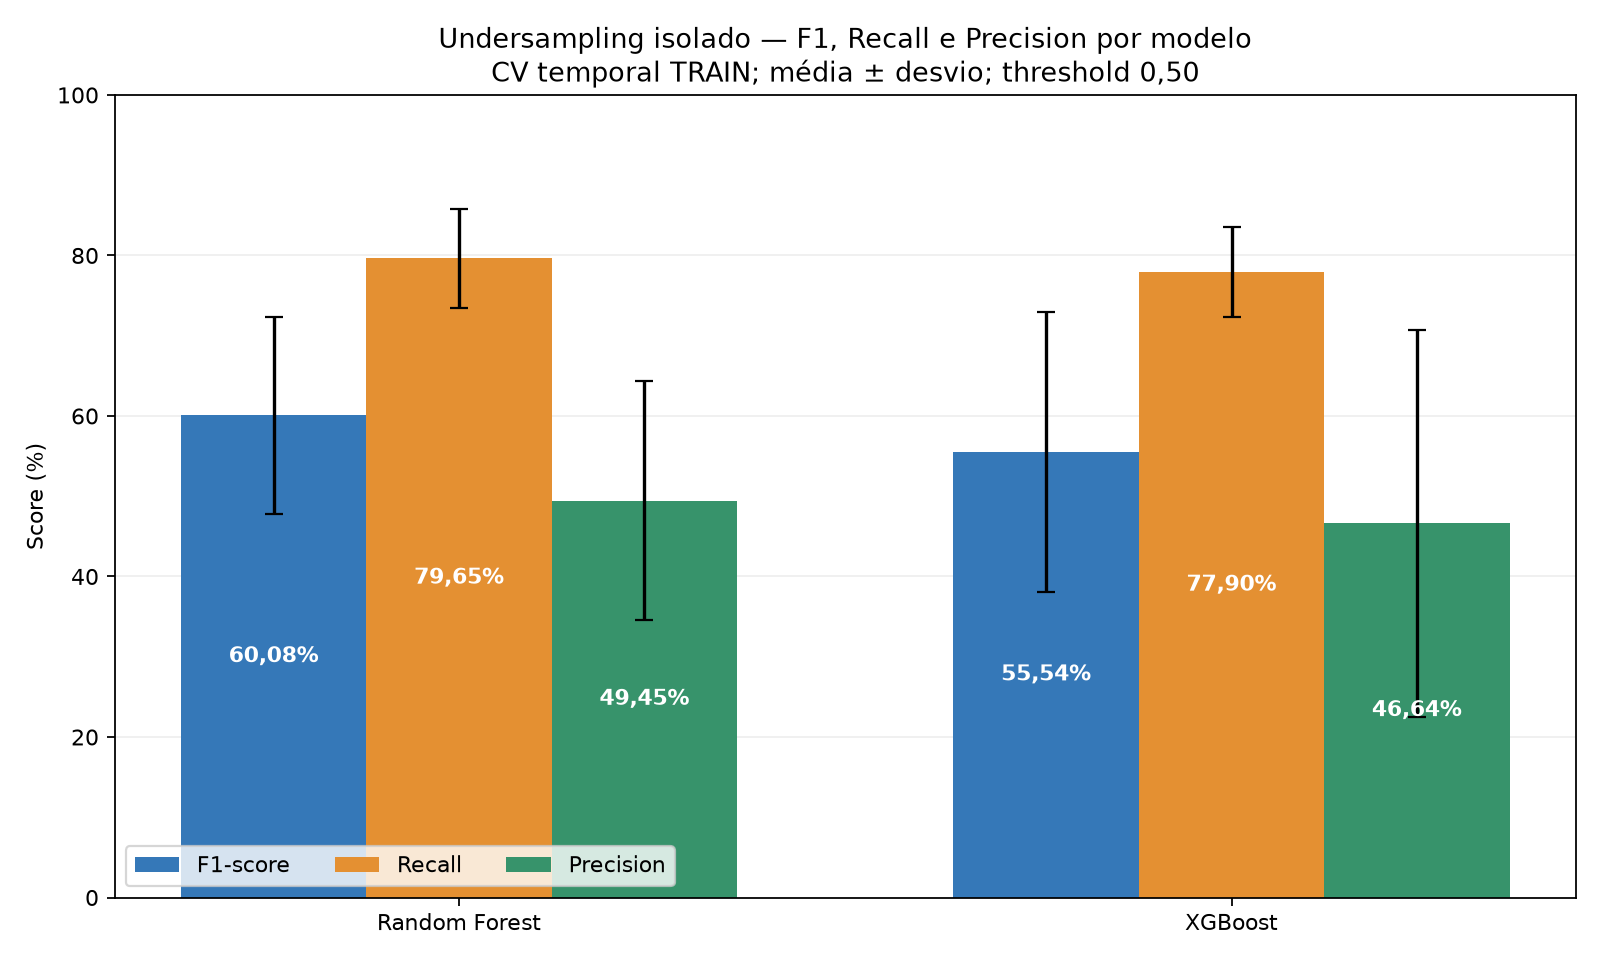

,Família,Delta F1 (p.p.),Delta Recall (p.p.),Delta Precision (p.p.),Delta AP (score)
0,random_forest,-16.4488,7.5036,-33.4103,-0.0066
1,xgboost,-22.0953,8.8961,-44.0415,-0.0153


Maior F1 entre os dois modelos deste sampler: **random_forest__under**. A estimativa do vencedor é condicionada à comparação nos mesmos folds.

In [3]:
comparison = table(f"{MODE}_model_comparison.csv")
show(comparison[[
    "strategy", "model", "f1", "f1_std", "recall", "recall_std",
    "precision", "precision_std", "average_precision", "fp", "fn"
]])
figure(f"{MODE}_comparison_f1_recall_precision.png")
all_comparison = table("sampling_comparison.csv").set_index("model")
changes = []
for family in ["random_forest", "xgboost"]:
    candidate = all_comparison.loc[f"{family}__{MODE}"]
    baseline = all_comparison.loc[f"{family}__none"]
    changes.append({
        "Família": family,
        "Delta F1 (p.p.)": 100*(candidate.f1-baseline.f1),
        "Delta Recall (p.p.)": 100*(candidate.recall-baseline.recall),
        "Delta Precision (p.p.)": 100*(candidate.precision-baseline.precision),
        "Delta AP (score)": candidate.average_precision-baseline.average_precision,
    })
display(pd.DataFrame(changes).style.format(precision=4))
winner = manifest["winners"][MODE]
display(Markdown(
    f"Maior F1 entre os dois modelos deste sampler: **{winner}**. "
    "A estimativa do vencedor é condicionada à comparação nos mesmos folds."
))


## 3. Folds, dispersão e generalização
Scores de treino são calculados na distribuição original do treino, apesar da
amostragem usada no fit. Scores de validação usam somente o período seguinte.
Uma grande diferença pode sugerir sobreajuste, mas também envolve mudança temporal.

O gráfico acompanha F1 de treino e validação. O treino cresce e os períodos mudam entre folds. Este gráfico **não é uma
learning curve controlada** nem demonstra isoladamente alto viés ou variância.

,Receita,Fold temporal,Features utilizadas,Limiar de alerta,train_average_precision,AP (score),train_f1,F1 (%),Recall (%),Precision (%),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas
6,random_forest__under,1,16,"0,5000","0,8400","0,7441",73.26%,67.38%,75.00%,61.17%,63,40,21,58.465
7,random_forest__under,2,15,"0,5000","0,7749","0,8150",79.09%,66.91%,86.67%,54.49%,91,76,14,51.523
8,random_forest__under,3,14,"0,5000","0,8544","0,6692",76.49%,45.95%,77.27%,32.69%,34,70,10,54.045
9,xgboost__under,1,16,"0,5000","0,8840","0,7456",77.97%,72.62%,72.62%,72.62%,61,23,23,58.482
10,xgboost__under,2,15,"0,5000","0,7395","0,7896",68.04%,56.23%,83.81%,42.31%,88,120,17,51.479
11,xgboost__under,3,14,"0,5000","0,8506","0,7239",72.49%,37.78%,77.27%,25.00%,34,102,10,54.013


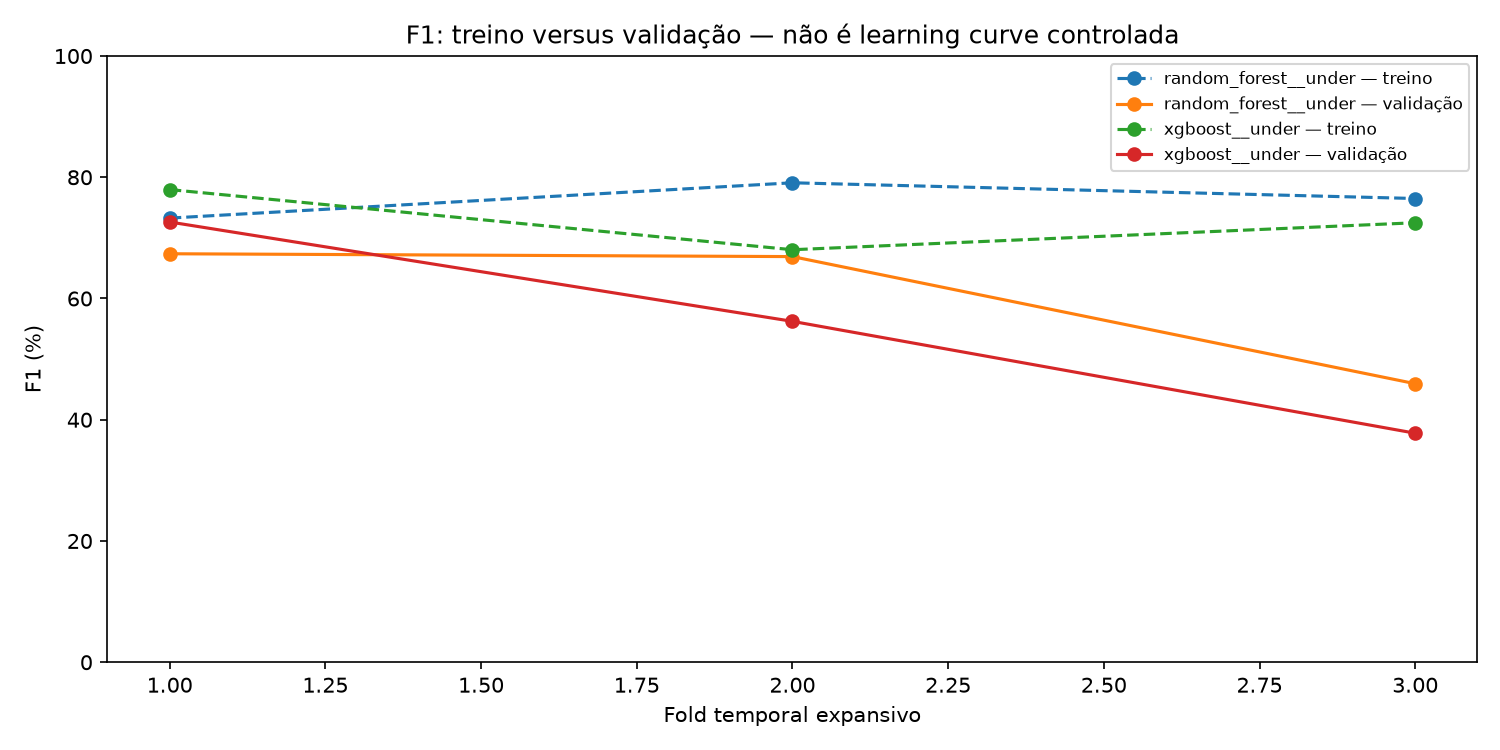

In [4]:
fold_scores = table("sampling_folds.csv")
show(fold_scores.loc[fold_scores.strategy.eq(MODE), [
    "model", "fold", "n_features", "threshold", "train_average_precision",
    "average_precision", "train_f1", "f1", "recall", "precision", "tp", "fp", "fn", "tn"
]])
figure(f"{MODE}_train_validation.png")

## 4. XGBoost: comportamento por número de árvores
AP e Log Loss foram calculados em pontos prefixados no último fold temporal.
Treino e validação continuam separados. Não houve early stopping, tuning de
n_estimators ou observação de TEST para decidir quantas árvores usar.

Learning rate, profundidade e regularização são os mesmos nas receitas.
Uma curva de validação que estabiliza enquanto treino melhora pode motivar
outro experimento, mas nenhum parâmetro foi alterado ao observar esta figura.

,Estratégia de balanceamento,trees,Origem,train_average_precision,train_log_loss,validation_average_precision,validation_log_loss
0,under,10,Último fold temporal TRAIN,"0,7466","0,0657","0,7217","0,0674"
1,under,25,Último fold temporal TRAIN,"0,7563","0,0393","0,7365","0,0439"
2,under,50,Último fold temporal TRAIN,"0,8030","0,0219","0,7357","0,0266"
3,under,100,Último fold temporal TRAIN,"0,8202","0,0147","0,7288","0,0208"
4,under,200,Último fold temporal TRAIN,"0,8506","0,0119","0,7239","0,0171"


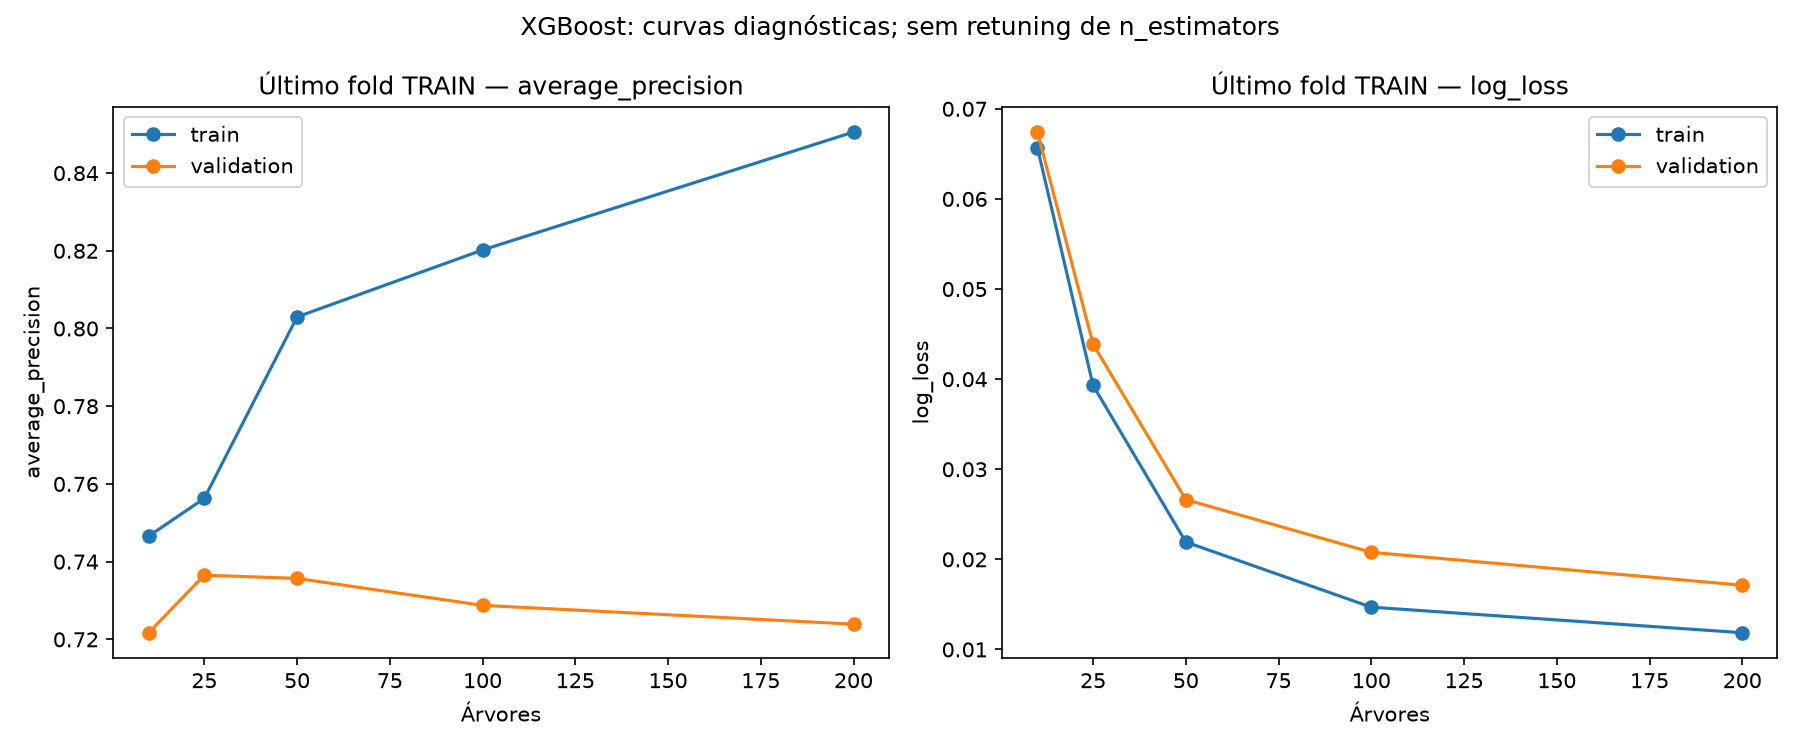

In [5]:
show(table(f"{MODE}_boosting_iterations.csv"))
figure(f"{MODE}_boosting_iterations.png")

## 5. OOF: matriz de confusão, PR/AP e ROC dos dois modelos
OOF temporal agrega previsões feitas em janelas posteriores ao fit dos modelos.
O prefixo inicial só treina e não tem previsão OOF. Todas as receitas têm a mesma
cobertura. A métrica OOF agregada não é a média dos scores dos folds.

A matriz usa threshold 0,50. Na PR, a linha de prevalência representa a referência
ingênua. AP usa scores contínuos e difere da área trapezoidal PR.
ROC-AUC complementa, mas não substitui Recall/Precision/AP para fraude rara.

Cobertura OOF: **164,452** transações, **78.2%** do TRAIN.

,Receita,Origem,rows,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta,alerts,Taxa de alertas (%)
2,random_forest__under,OOF temporal TRAIN agregado; prefixo inicial sem previsão,164.452,"0,7437",61.94%,80.69%,50.27%,"0,9459",90.29%,99.89%,"0,0227","0,0025",164.033,186,45,188,"0,5000",374,0.23%
3,xgboost__under,OOF temporal TRAIN agregado; prefixo inicial sem previsão,164.452,"0,7336",55.37%,78.54%,42.76%,"0,9563",89.20%,99.85%,"0,0121","0,0017",163.974,245,50,183,"0,5000",428,0.26%
6,dummy,OOF temporal TRAIN agregado; prefixo inicial sem previsão,164.452,"0,0016",0.00%,0.00%,0.00%,"0,5467",50.00%,100.00%,"0,0110","0,0014",164.219,0,233,0,"0,5000",0,0.00%


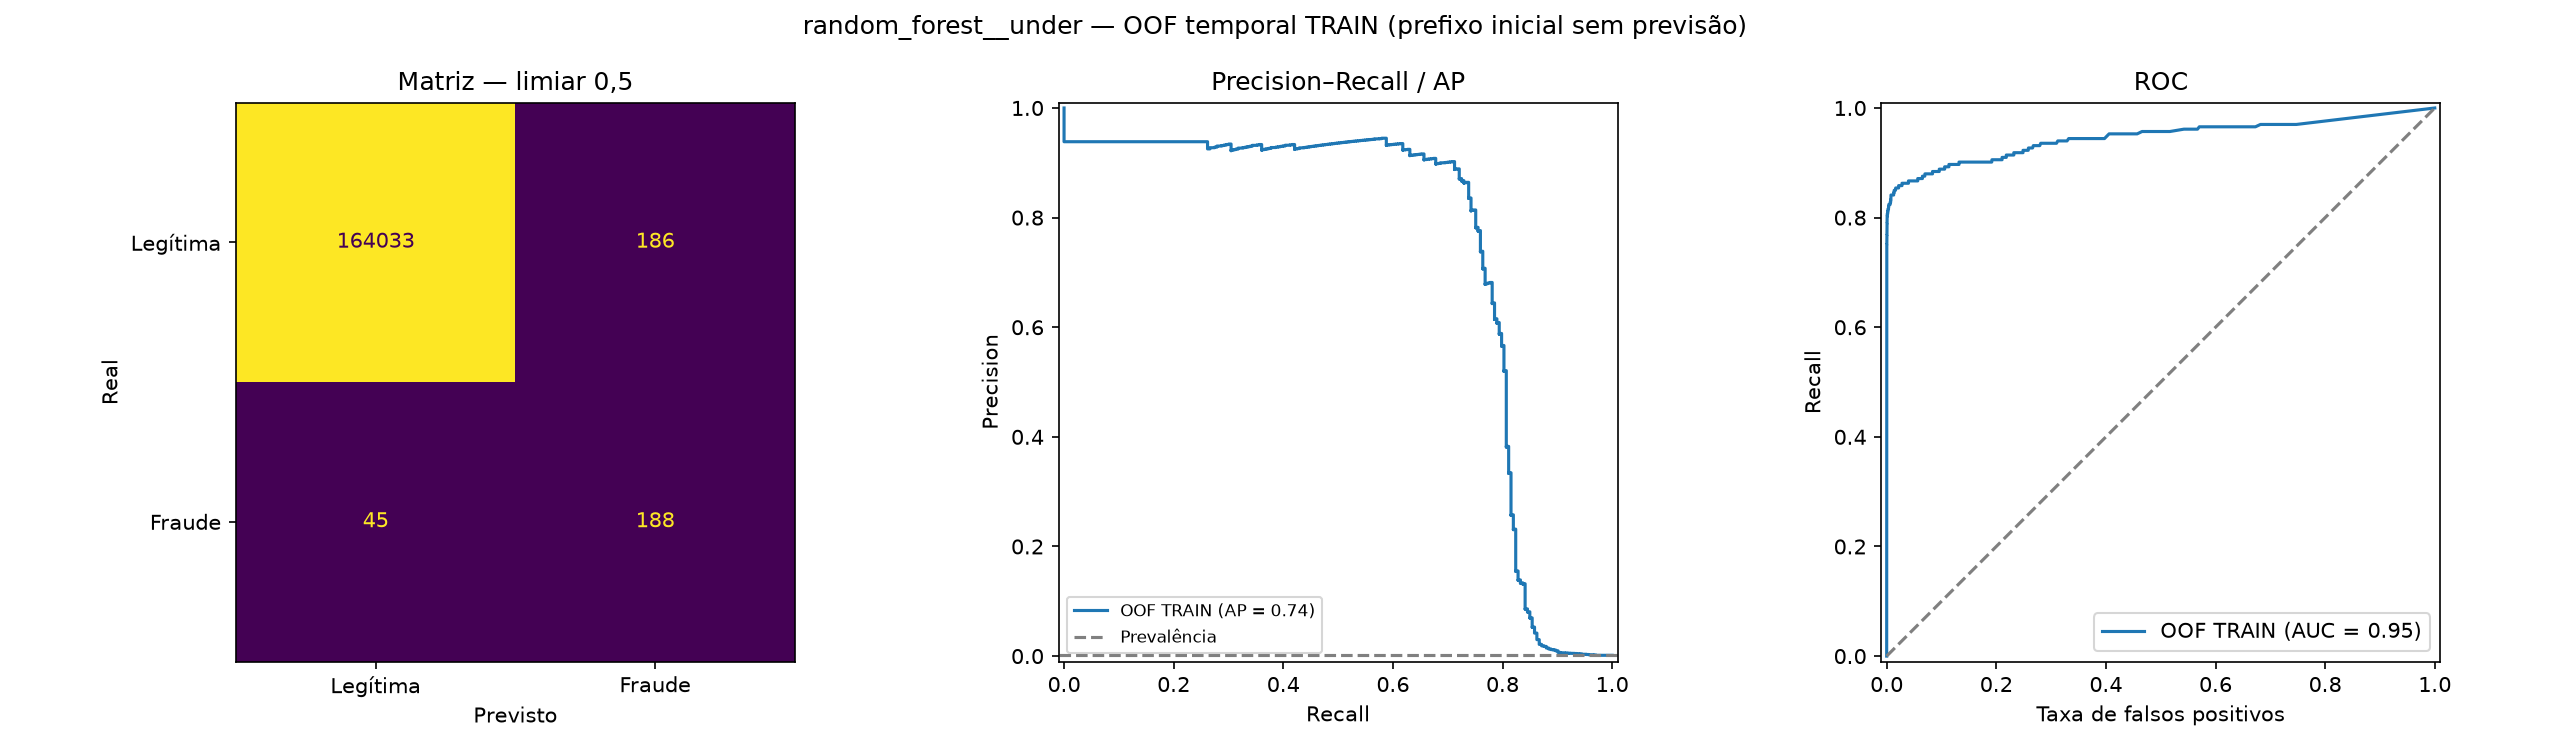

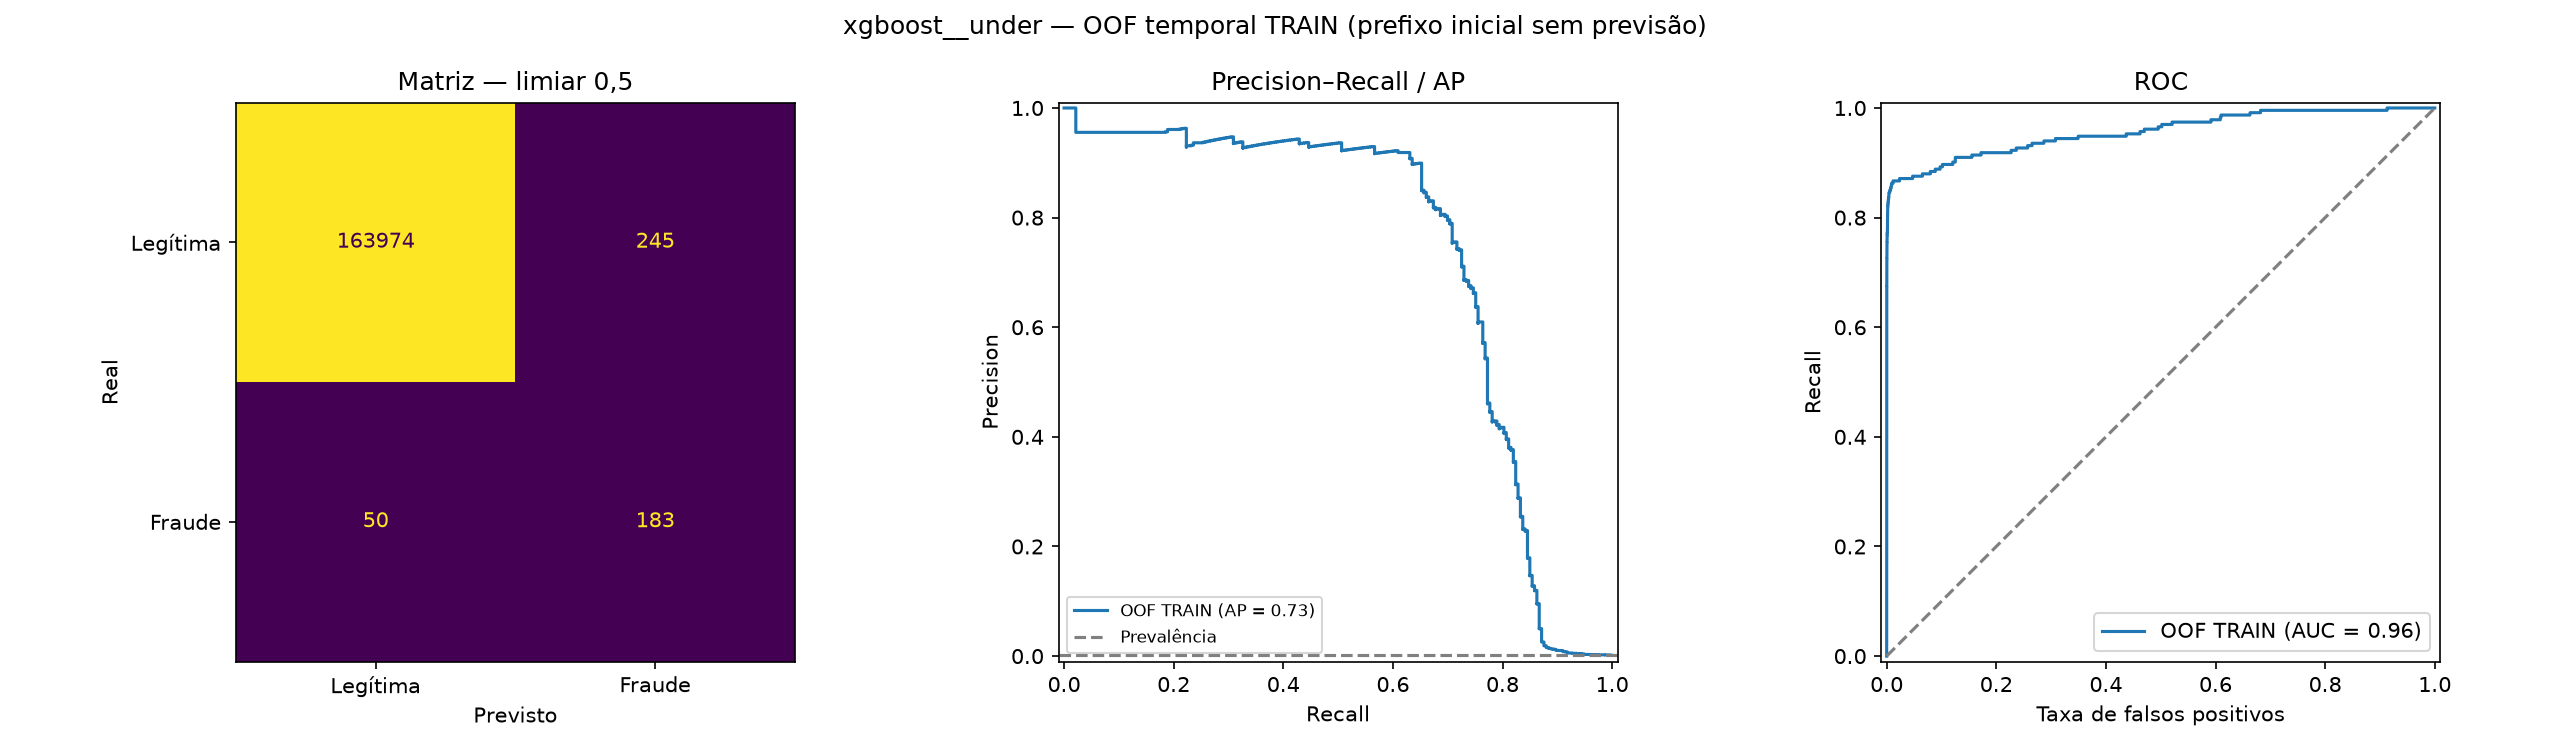

In [6]:
display(Markdown(
    f"Cobertura OOF: **{manifest['oof_rows']:,}** transações, "
    f"**{manifest['oof_coverage']:.1%}** do TRAIN."
))
oof = table("sampling_oof_metrics.csv")
show(oof.loc[oof.model.isin([f"random_forest__{MODE}", f"xgboost__{MODE}", "dummy"])])
figure(f"{MODE}_random_forest_oof.png", 1300)
figure(f"{MODE}_xgboost_oof.png", 1300)

## 6. Correlação com a target versus importância
Pearson/Spearman usam TRAIN completo como diagnóstico. A permutação mede queda
de AP na última validação do TRAIN com o estimador que não treinou naquela janela.
A escolha de modelo já usou validação: importância é descritiva após comparação.

Os painéis têm escalas distintas. Correlação e importância não implicam causalidade.
A tabela também traz importância interna da árvore, que tem vieses e pode dividir
crédito entre variáveis correlacionadas. Colunas retiradas recebem importância zero
no pipeline porque não são usadas, não como prova geral de irrelevância.
Este diagnóstico não elimina outras features nem altera os cortes da regra.

,Feature,Usada no último fold?,Pearson com Class,Spearman com Class,Queda de AP por permutação,Desvio da permutação,Importância interna da árvore
0,Time,False,"-0,0140","-0,0135","0,0000","0,0000","0,0000"
1,V1,True,"-0,1153","-0,0448","0,0046","0,0028","0,0094"
2,V2,True,"0,1017","0,0544","0,0002","0,0064","0,0114"
3,V3,True,"-0,2197","-0,0610","0,0364","0,0287","0,0417"
4,V4,True,"0,1389","0,0640","0,0104","0,0205","0,0435"
5,V5,True,"-0,1154","-0,0366","-0,0105","0,0016","0,0089"
6,V6,False,"-0,0475","-0,0401","0,0000","0,0000","0,0000"
7,V7,True,"-0,2106","-0,0497","0,0180","0,0132","0,0249"
8,V8,False,"0,0406","0,0240","0,0000","0,0000","0,0000"
9,V9,True,"-0,1007","-0,0493","0,0106","0,0103","0,0109"


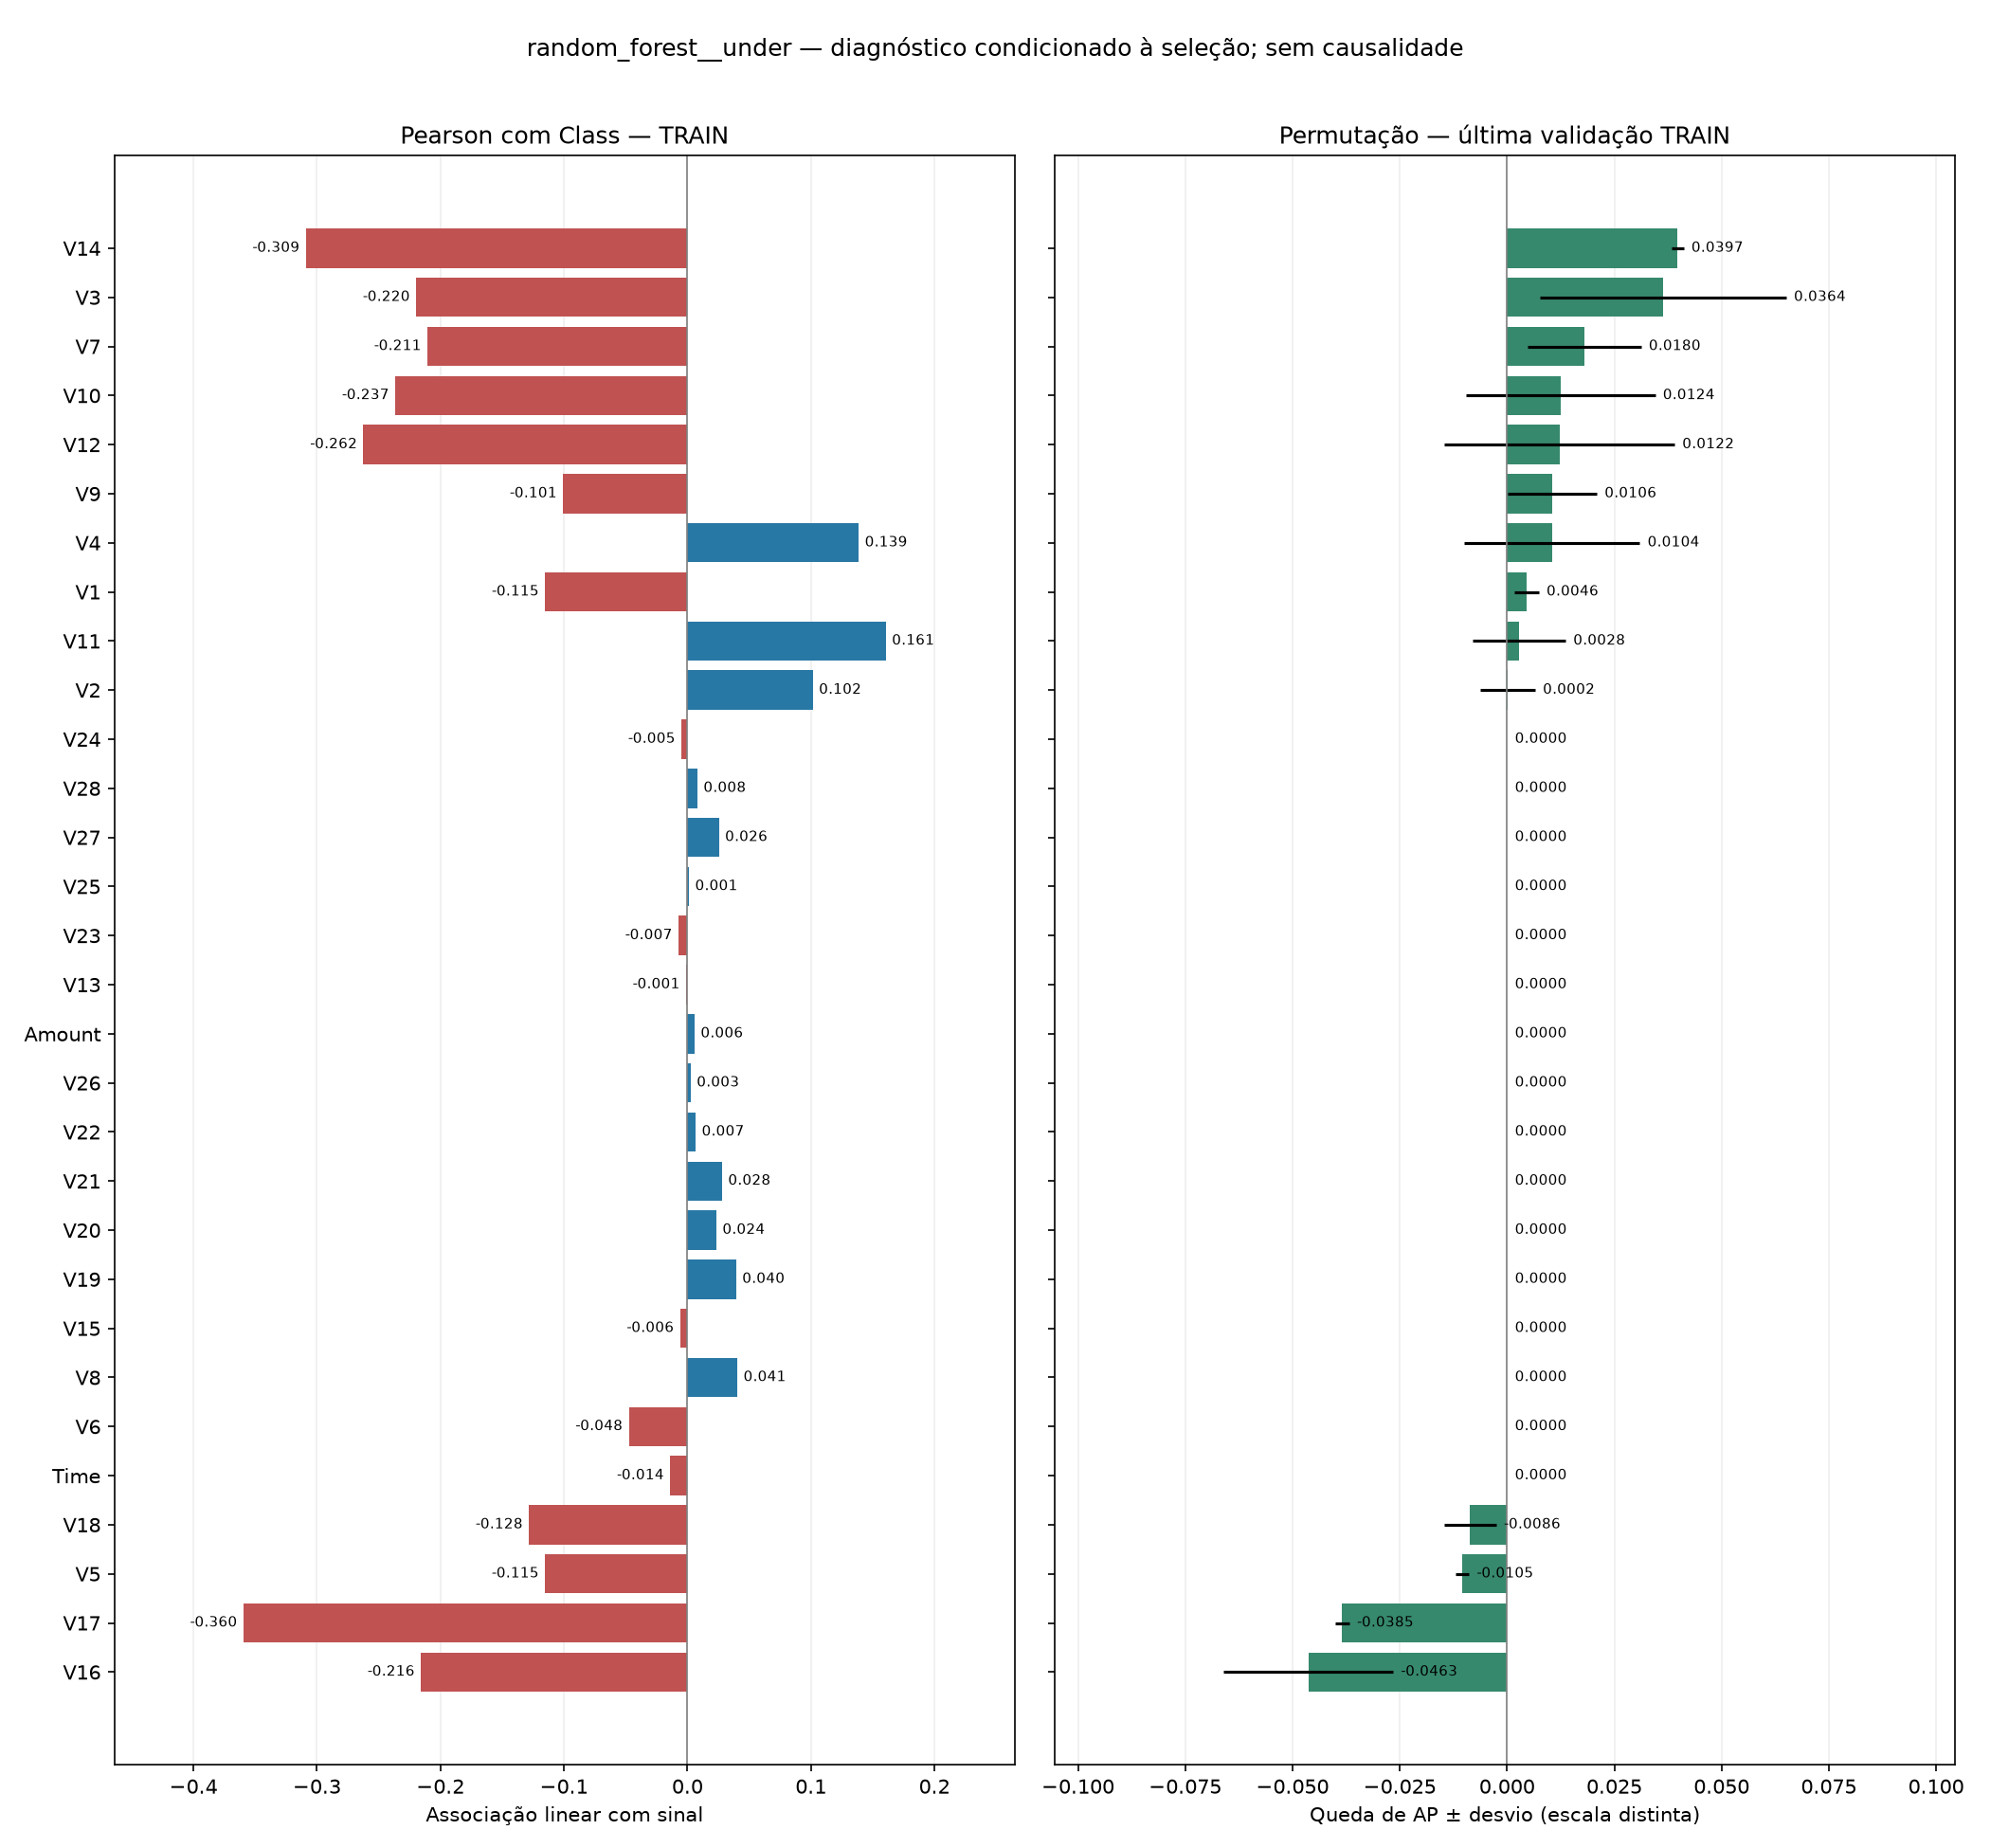

,Feature,Usada no último fold?,Pearson com Class,Spearman com Class,Queda de AP por permutação,Desvio da permutação,Importância interna da árvore
30,Time,False,"-0,0140","-0,0135","0,0000","0,0000","0,0000"
31,V1,True,"-0,1153","-0,0448","-0,0011","0,0060","0,0112"
32,V2,True,"0,1017","0,0544","0,0108","0,0038","0,0137"
33,V3,True,"-0,2197","-0,0610","0,0105","0,0046","0,0278"
34,V4,True,"0,1389","0,0640","0,1905","0,0072","0,0393"
35,V5,True,"-0,1154","-0,0366","-0,0115","0,0068","0,0153"
36,V6,False,"-0,0475","-0,0401","0,0000","0,0000","0,0000"
37,V7,True,"-0,2106","-0,0497","0,0249","0,0143","0,0183"
38,V8,False,"0,0406","0,0240","0,0000","0,0000","0,0000"
39,V9,True,"-0,1007","-0,0493","0,0034","0,0047","0,0136"


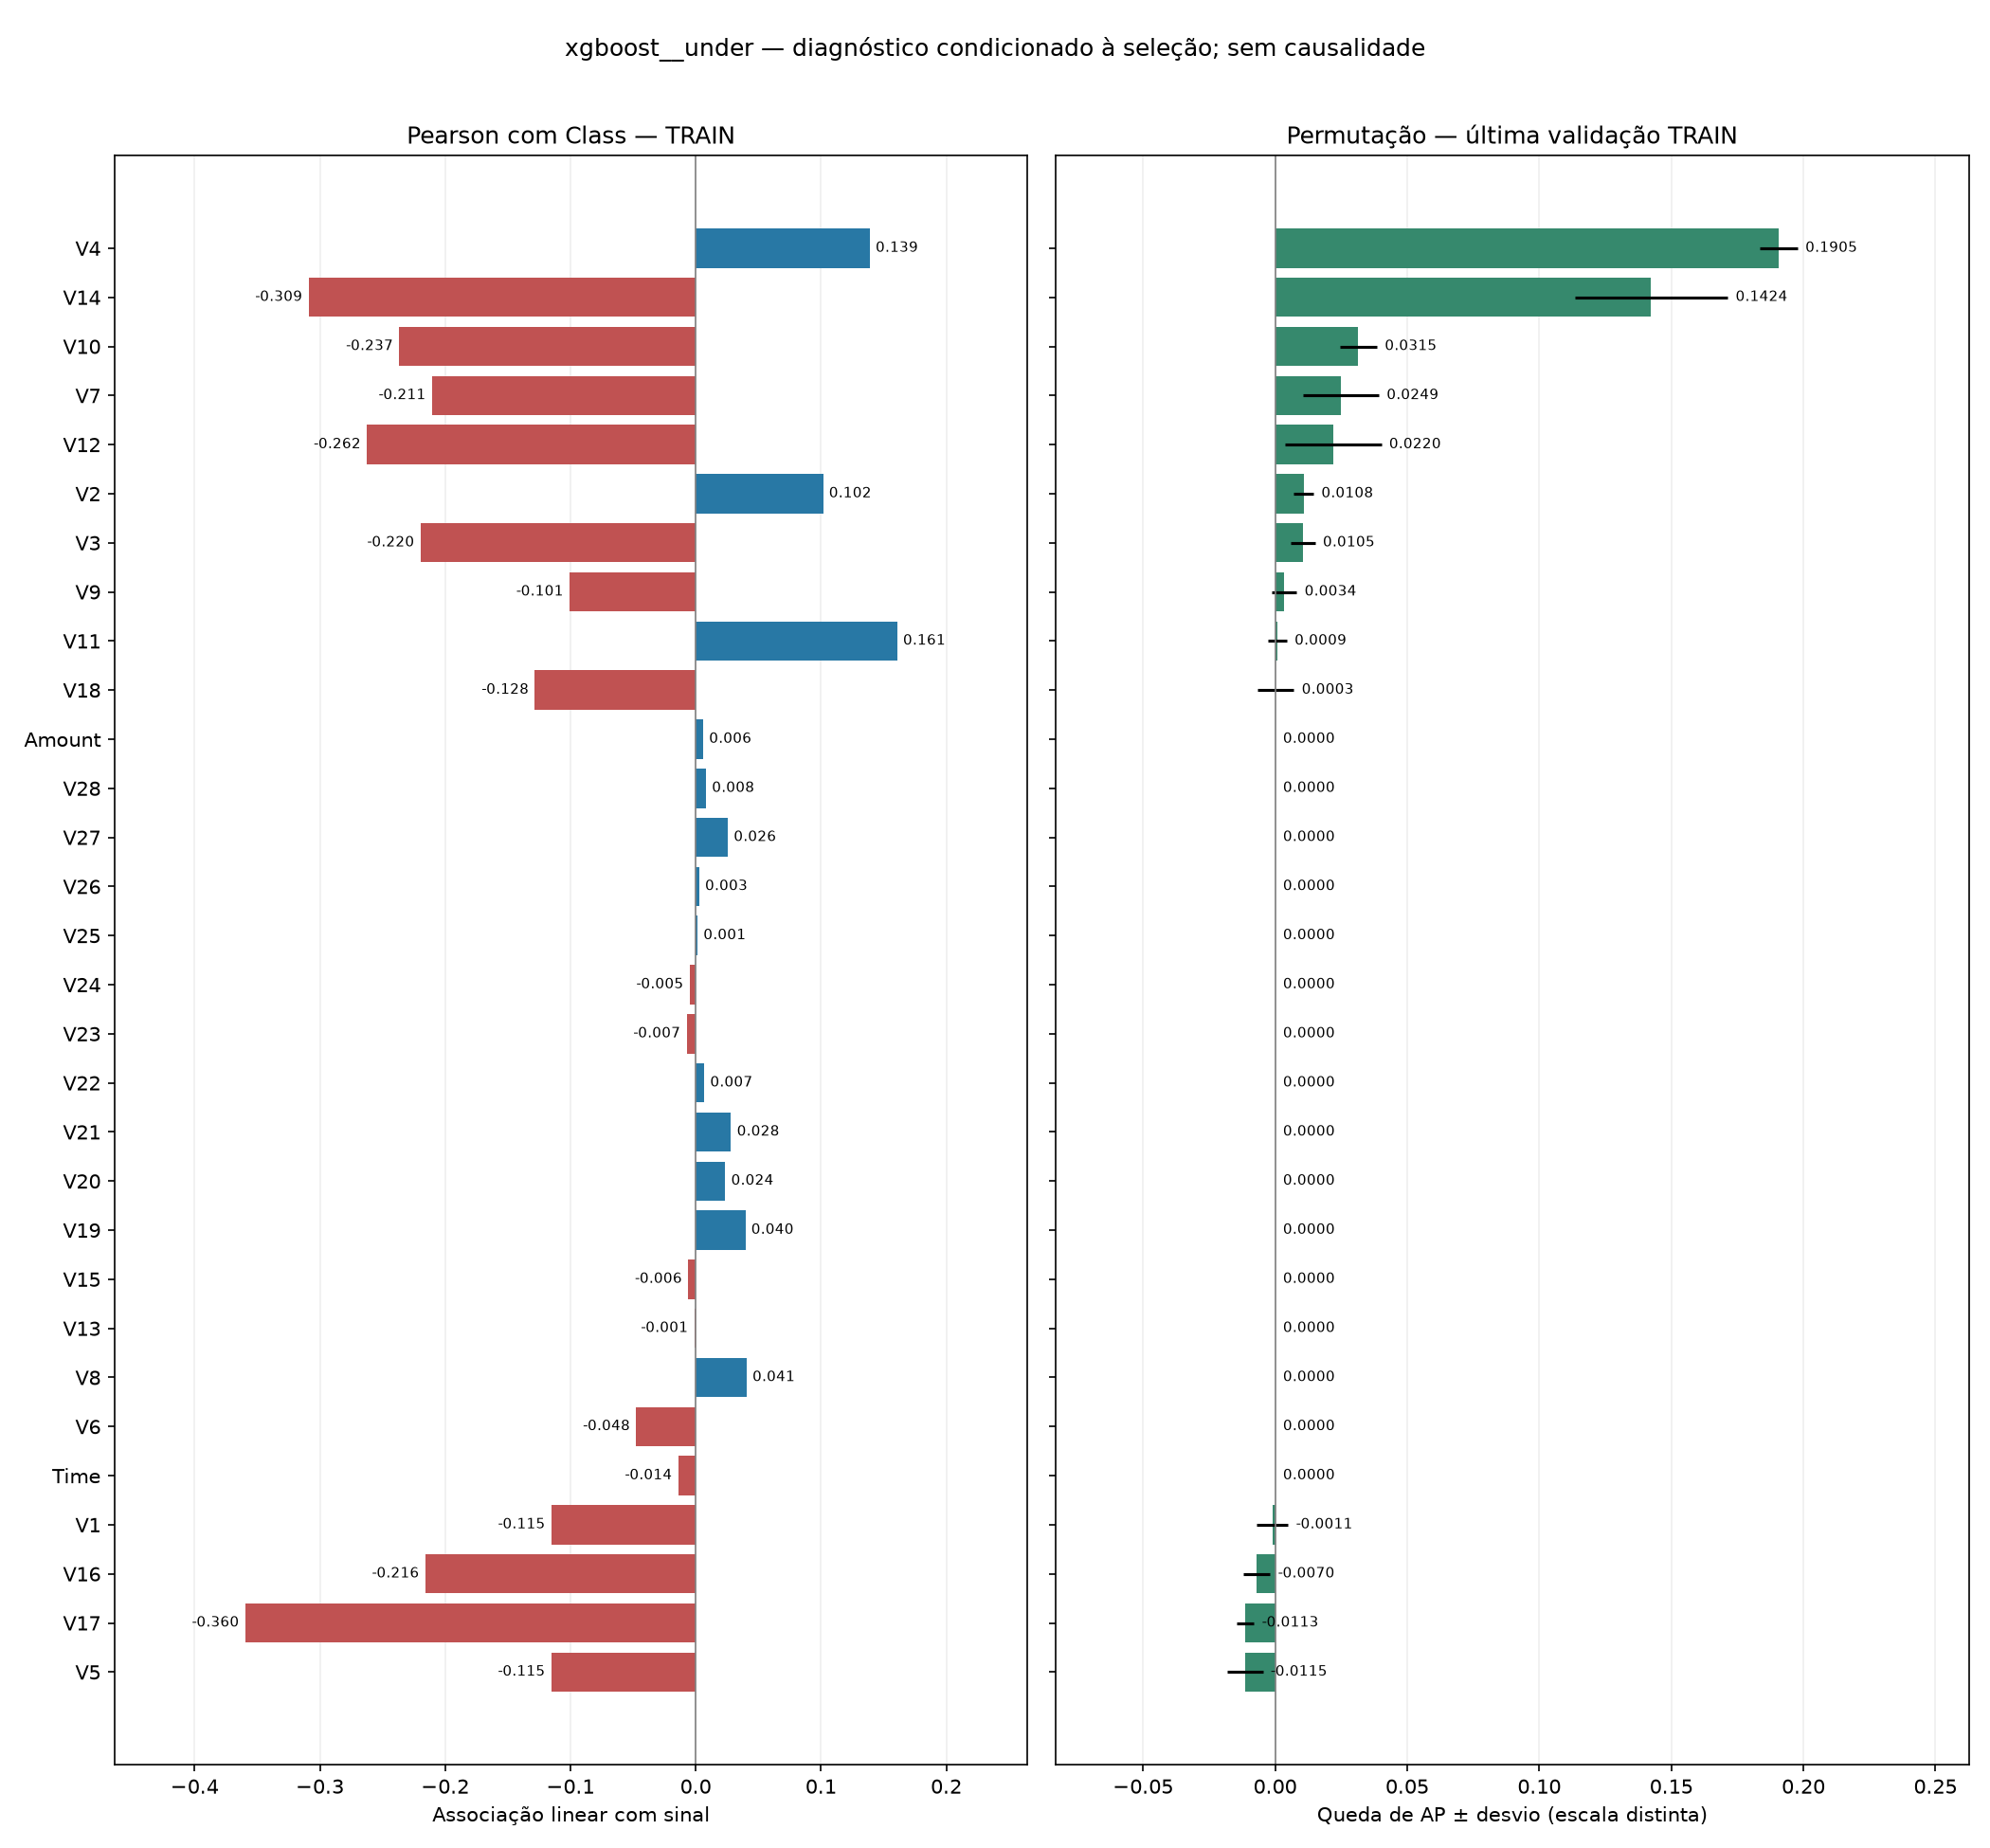

In [7]:
association = table(f"{MODE}_association_importance.csv")
for family in ["random_forest", "xgboost"]:
    model = f"{family}__{MODE}"
    show(association.loc[association.model.eq(model), [
        "feature", "selected_last_fold", "pearson", "spearman",
        "permutation_ap", "permutation_std", "tree_importance"
    ]])
    figure(f"{MODE}_{family}_association_importance.png", 1100)

## 7. Diversidade de erros alinhados
Disagreement é a fração em que os rótulos previstos pelos dois modelos diferem.
Double-fault é a fração em que ambos erram; os demais campos separam acertos
conjuntos e erros exclusivos. Comparações usam as mesmas transações OOF.

Alta discordância ou baixa double-fault, sozinhas, não provam benefício de
Voting/Stacking. Nenhum ensemble adicional foi ajustado nesta rodada.

In [8]:
show(table(f"{MODE}_error_diversity.csv"))

,model_a,model_b,Origem,disagreement,double_fault,both_correct,only_a_wrong,only_b_wrong
0,random_forest,xgboost,OOF temporal TRAIN alinhado,0.14%,0.09%,99.77%,0.05%,0.09%


## 8. Barras agrupadas por threshold — somente diagnóstico
Estas barras agrupadas usam a última janela de validação dentro do TRAIN. Mostram a troca
entre Recall, Precision e F1 quando o ponto de decisão varia sobre os mesmos scores.
**Nenhuma figura escolheu outro limiar:** toda a comparação principal continua em 0,50.

Amostragem pode alterar o significado das probabilidades. Não há calibração
demonstrada, e o limiar comum não foi alegado como ótimo para cada receita.
Uma futura busca de limiar precisa de validação interna apropriada e avaliação
externa ao ajuste, com o mesmo protocolo para todos os métodos.

,Receita,Limiar de alerta,F1 (%),Recall (%),Precision (%),FP: falsos alertas,FN: fraudes não detectadas,alerts
0,random_forest__under,"0,0100",0.33%,100.00%,0.17%,26.480,0,26.524
1,random_forest__under,"0,0500",0.90%,97.73%,0.45%,9.417,1,9.460
2,random_forest__under,"0,1000",2.25%,88.64%,1.14%,3.381,5,3.420
3,random_forest__under,"0,2000",11.80%,84.09%,6.35%,546,7,583
4,random_forest__under,"0,3000",18.51%,81.82%,10.43%,309,8,345
5,random_forest__under,"0,4000",28.57%,79.55%,17.41%,166,9,201
6,random_forest__under,"0,5000",45.95%,77.27%,32.69%,70,10,104
7,random_forest__under,"0,6000",54.84%,77.27%,42.50%,46,10,80
8,random_forest__under,"0,7000",64.15%,77.27%,54.84%,28,10,62
9,random_forest__under,"0,8000",73.33%,75.00%,71.74%,13,11,46


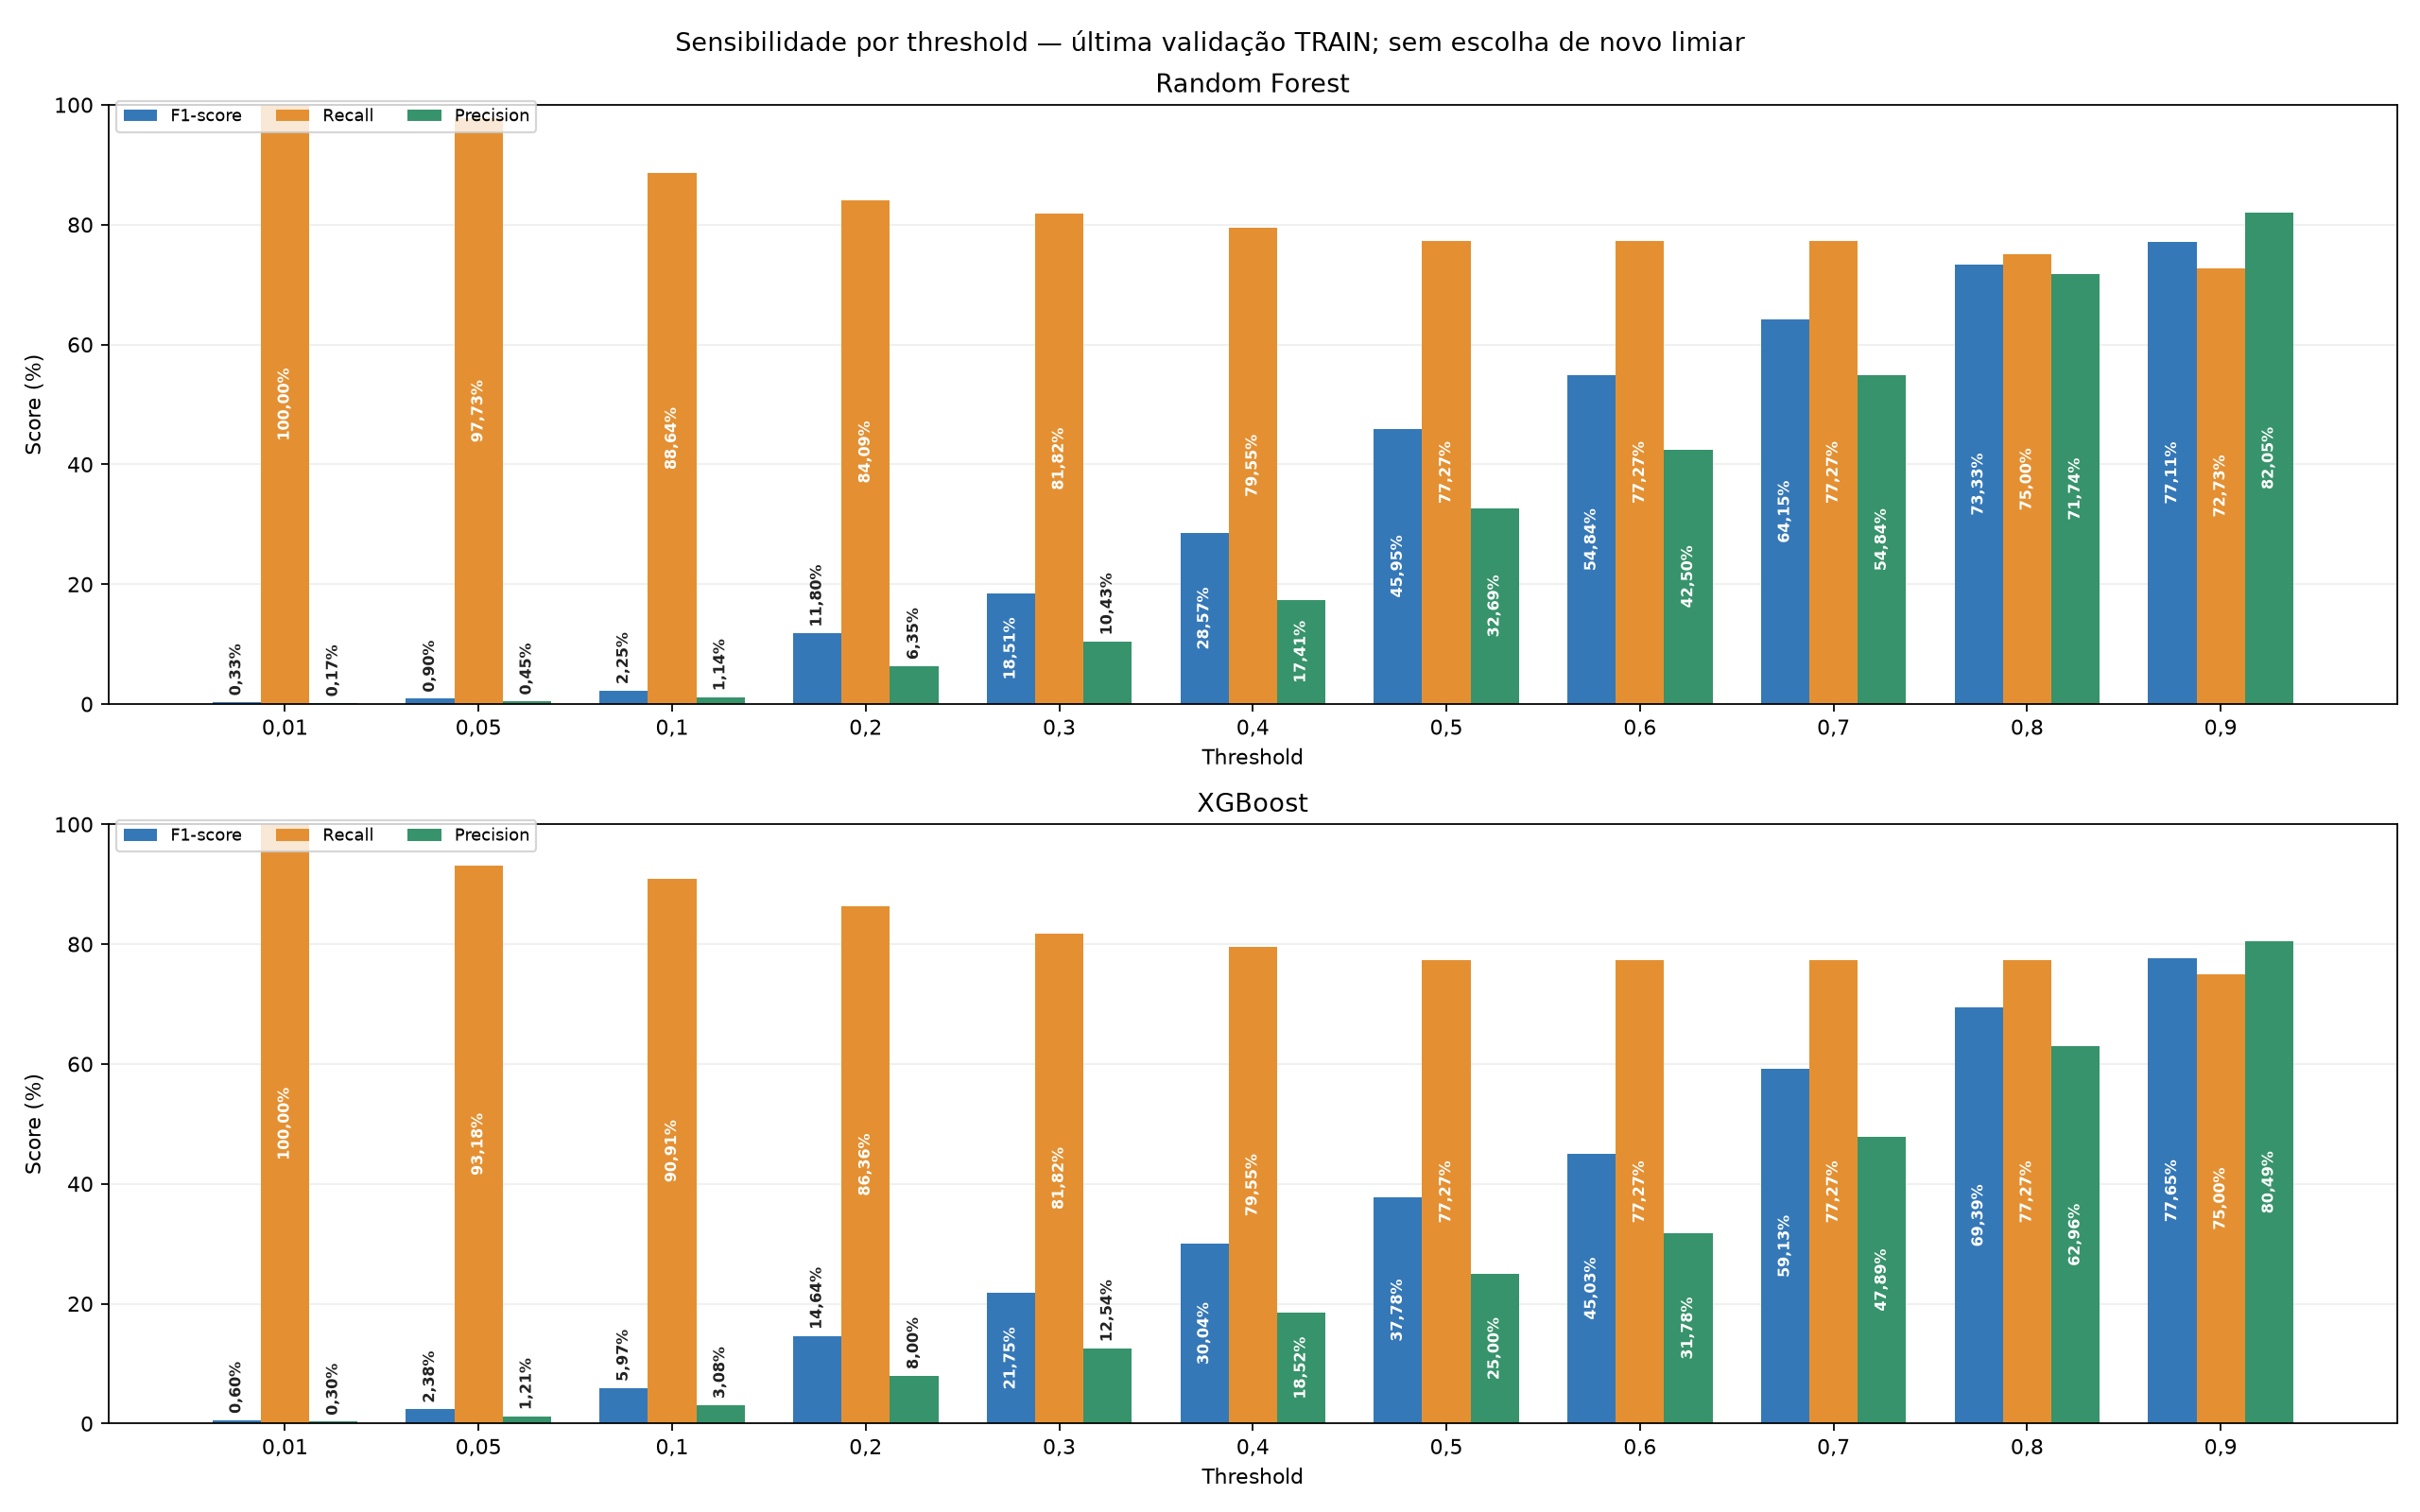

In [9]:
show(table(f"{MODE}_threshold_sensitivity.csv")[
    ["model", "threshold", "f1", "recall", "precision", "fp", "fn", "alerts"]
])
figure(f"{MODE}_threshold_sensitivity.png")

## 9. Fraude observada e erros por faixa de feature
As fronteiras das faixas são aprendidas no treino do fold e aplicadas à validação.
Cada linha identifica uma faixa de uma feature; não é uma modalidade real de fraude.

Taxa de fraude usa todas as transações da faixa; Recall usa suas fraudes;
Precision usa seus alertas. FPR usa as legítimas, enquanto parcela de alertas
falsos usa os alertas. Taxas com poucas fraudes exigem leitura junto às contagens.
“Não definido” indica denominador zero. Não some faixas de features diferentes,
pois as mesmas transações reaparecem em cada feature.

In [10]:
FEATURE_TO_INSPECT = "V10"
errors = table(f"{MODE}_category_errors.csv")
show(errors.loc[
    errors.model.eq(winner) & errors.feature.eq(FEATURE_TO_INSPECT),
    ["model", "fold", "feature", "bin", "count", "fraud_count",
     "tp", "fp", "fn", "tn", "fraud_rate_pct", "recall_pct", "precision_pct",
     "false_positive_rate_pct", "false_alert_share_pct"]
])
display(Markdown(
    f"O CSV **reports/metrics/{MODE}_category_errors.csv** contém todas as features "
    "e os dois modelos. Altere FEATURE_TO_INSPECT para outro recorte."
))

,Receita,Fold temporal,Feature,Faixa de valores,Quantidade,Fraudes confirmadas,TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas,Fraude na faixa (%),Recall da faixa (%),Precision da faixa (%),Falsos positivos entre legítimas (%),Alertas que eram falsos (%)
91,random_forest__under,1,V10,"(-1.057, -0.657]",5.077,2,0,1,2,5.074,0.0394%,0.00%,0.00%,0.02%,100.00%
92,random_forest__under,1,V10,"(-0.28, -0.12]",6.840,3,0,0,3,6.837,0.0439%,0.00%,Não definido,0.00%,Não definido
93,random_forest__under,1,V10,"(-inf, -1.057]",4.413,64,62,9,2,4.340,1.4503%,96.88%,87.32%,0.21%,12.68%
94,random_forest__under,1,V10,"(-0.443, -0.28]",5.488,3,0,0,3,5.485,0.0547%,0.00%,Não definido,0.00%,Não definido
95,random_forest__under,1,V10,"(-0.657, -0.443]",5.184,3,0,0,3,5.181,0.0579%,0.00%,Não definido,0.00%,Não definido
96,random_forest__under,1,V10,"(0.57, 0.89]",6.340,0,0,0,0,6.340,0.0000%,Não definido,Não definido,0.00%,Não definido
97,random_forest__under,1,V10,"(0.0218, 0.232]",6.192,2,1,0,1,6.190,0.0323%,50.00%,100.00%,0.00%,0.00%
98,random_forest__under,1,V10,"(0.89, inf]",6.289,1,0,30,1,6.258,0.0159%,0.00%,0.00%,0.48%,100.00%
99,random_forest__under,1,V10,"(-0.12, 0.0218]",7.214,3,0,0,3,7.211,0.0416%,0.00%,Não definido,0.00%,Não definido
100,random_forest__under,1,V10,"(0.232, 0.57]",5.552,3,0,0,3,5.549,0.0540%,0.00%,Não definido,0.00%,Não definido


O CSV **reports/metrics/under_category_errors.csv** contém todas as features e os dois modelos. Altere FEATURE_TO_INSPECT para outro recorte.

## 10. Conclusão e limites
A comparação utiliza a mesma base, folds, features por fold, StandardScaler,
hiperparâmetros, pesos uniformes e threshold. As diferenças observadas descrevem
essas receitas e razão de amostragem, não uma superioridade universal do método.

Os folds e o TRAIN já participaram de rodadas anteriores. Desvio entre folds
não é intervalo de confiança, e diferenças pequenas não provam superioridade
estatística. O dataset cobre apenas dois dias; não há IDs para separar cartões
nem metadados que permitam auditar o PCA fornecido.

**TEST não foi avaliado novamente. O artefato histórico com threshold 0,70 permanece intacto.**
Esta rodada gera relatórios de CV, não promove/refaz outro modelo final.
Novas escolhas e ajuste de limiar precisam de validação apropriada, e outro período
externo é necessário para confirmar generalização após todas essas iterações.

In [11]:
for change in changes:
    display(Markdown(
        f"**{change['Família']}** frente ao controle sem sampler: "
        f"F1 **{change['Delta F1 (p.p.)']:+.2f} p.p.**; "
        f"Recall **{change['Delta Recall (p.p.)']:+.2f} p.p.**; "
        f"Precision **{change['Delta Precision (p.p.)']:+.2f} p.p.**."
    ))
display(manifest["limitations"])


**random_forest** frente ao controle sem sampler: F1 **-16.45 p.p.**; Recall **+7.50 p.p.**; Precision **-33.41 p.p.**.

**xgboost** frente ao controle sem sampler: F1 **-22.10 p.p.**; Recall **+8.90 p.p.**; Precision **-44.04 p.p.**.

['Mesmos folds TRAIN reutilizados de rodadas anteriores; comparação exploratória.',
 'Importância é diagnóstico condicionado à seleção; não confirma causalidade.',
 'Threshold 0.5 fixado para isolar receitas; sensibilidade não seleciona outro limiar.',
 'Mudanças de prevalência de treino podem afetar probabilidades não calibradas.',
 'SMOTENC não se aplica às entradas exclusivamente numéricas deste dataset.',
 'Não há novo refit/promoção de modelo nem avaliação do TEST histórico nesta rodada.']